In [ ]:
!pip uninstall -y opencv-python opencv-python-headless numpy



Found existing installation: opencv-python 4.11.0.86
Uninstalling opencv-python-4.11.0.86:
  Successfully uninstalled opencv-python-4.11.0.86
Found existing installation: opencv-python-headless 4.8.0.76
Uninstalling opencv-python-headless-4.8.0.76:
  Successfully uninstalled opencv-python-headless-4.8.0.76
Found existing installation: numpy 1.26.4
Uninstalling numpy-1.26.4:
  Successfully uninstalled numpy-1.26.4


In [ ]:
!pip install numpy==1.26.4 opencv-python-headless==4.8.0.76 deepface norfair


  Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
  Using cached opencv_python_headless-4.8.0.76-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (19 kB)
  Using cached opencv_python-4.12.0.88-cp37-abi3-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (19 kB)
INFO: pip is looking at multiple versions of opencv-python to determine which version is compatible with other requirements. This could take a while.
  Using cached opencv_python-4.11.0.86-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.3 MB)
Using cached opencv_python_headless-4.8.0.76-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (49.1 MB)
Using cached opencv_python-4.11.0.86-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (63.0 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages t

In [9]:
import cv2
import numpy as np
from deepface import DeepFace
from norfair import Detection, Tracker

print("✅ OpenCV sürümü:", cv2.__version__)
print("✅ NumPy sürümü:", np.__version__)

# Basit bir DeepFace fonksiyon testi
try:
    dummy = np.zeros((100, 100, 3), dtype=np.uint8)
    result = DeepFace.analyze(dummy, actions=['emotion'], enforce_detection=False)
    print("✅ DeepFace çalışıyor. Tespit edilen duygu:", result[0]["dominant_emotion"])
except Exception as e:
    print("❌ DeepFace hata verdi:", e)

# Norfair tracker test
try:
    tracker = Tracker(distance_function="euclidean", distance_threshold=30)
    print("✅ Norfair çalışıyor.")
except Exception as e:
    print("❌ Norfair hata verdi:", e)


✅ OpenCV sürümü: 4.11.0
✅ NumPy sürümü: 1.26.4
✅ DeepFace çalışıyor. Tespit edilen duygu: angry
✅ Norfair çalışıyor.


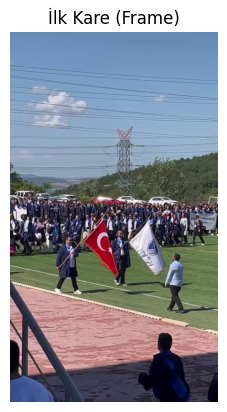

In [10]:
import cv2
import matplotlib.pyplot as plt

video_path = "/content/WhatsApp Video 2025-07-10 saat 22.54.51_d370ece6.mp4"  # Burayı dosya adına göre değiştir (örnek: video.mp4)

cap = cv2.VideoCapture(video_path)

ret, frame = cap.read()  # İlk kareyi al
# frame: Okunan görüntüdür, NumPy dizisidir ((yükseklik, genişlik, 3) şeklinde).


if ret:
    # OpenCV’de BGR formatındakini matplotlib için RGB çevir
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # Görüntüyü göster
    plt.imshow(frame_rgb)
    plt.axis('off')
    plt.title("İlk Kare (Frame)")
    plt.show()
else:
    print("❌ Video okunamadı. Yol veya format hatası olabilir.")


In [11]:
from deepface import DeepFace
import cv2
import math
import numpy as np
from norfair import Detection, Tracker


In [12]:
def format_time(seconds):
    mins = int(seconds // 60)
    secs = int(seconds % 60)
    millis = int((seconds - int(seconds)) * 100)
    return f"{mins:02d}:{secs:02d}.{millis:02d}"


In [13]:
from deepface import DeepFace
import cv2
import math
import numpy as np
from norfair import Detection, Tracker

prev_positions = {}  # face_id -> (cx, cy)

cap = cv2.VideoCapture(video_path)
tracker = Tracker(distance_function="euclidean", distance_threshold=40)

fps = cap.get(cv2.CAP_PROP_FPS)
frame_number = 0
frame_results = []
results = []

while True:
    ret, frame = cap.read()
    if not ret:
        break

    if frame_number % 5 == 0:
        frame = cv2.resize(frame, (640, 360))
        timestamp = frame_number / fps

        try:
            analysis = DeepFace.analyze(frame,
                                       actions=['gender', 'emotion'],
                                       detector_backend="retinaface",
                                       enforce_detection=True)

            if isinstance(analysis, dict):
                analysis = [analysis]

            if len(analysis) == 0:
                frame_number += 1
                continue

            face_centers = []
            for person in analysis:
                region = person.get('region', {})
                x, y, w, h = region.get('x', 0), region.get('y', 0), region.get('w', 50), region.get('h', 50)
                cx, cy = x + w // 2, y + h // 2
                face_centers.append((cx, cy))

            norfair_detections = [Detection(points=np.array([[cx, cy]])) for cx, cy in face_centers]

            tracked_objects = tracker.update(detections=norfair_detections)

            face_ids = []
            for cx, cy in face_centers:
                matched_id = -1
                min_dist = float("inf")
                for obj in tracked_objects:
                    tx, ty = obj.estimate[0]
                    dist = math.hypot(tx - cx, ty - cy)
                    if dist < min_dist:
                        min_dist = dist
                        matched_id = obj.id
                face_ids.append(matched_id)

            genders, emotions, speeds, angles = [], [], [], []

            for i, person in enumerate(analysis):
                dominant_gender = person.get('dominant_gender')
                dominant_emotion = person.get('dominant_emotion')
                region = person.get('region', {})
                x, y, w, h = region.get('x', 0), region.get('y', 0), region.get('w', 50), region.get('h', 50)
                cx, cy = x + w // 2, y + h // 2

                matched_id = face_ids[i]

                if matched_id in prev_positions:
                    px, py = prev_positions[matched_id]
                    dx = cx - px
                    dy = cy - py
                    dt = 5 / fps

                    if abs(dx) < 2 and abs(dy) < 2:
                        speed = 0.0
                        angle = 0.0
                        label = f"{dominant_gender}, {dominant_emotion}, hareket yok"
                    else:
                        speed = math.sqrt(dx**2 + dy**2) / dt
                        angle = math.degrees(math.atan2(dy, dx))
                        cv2.arrowedLine(frame, (px, py), (cx, cy), (0, 255, 0), 2, tipLength=0.3)
                        label = f"{dominant_gender}, {dominant_emotion}, {speed:.1f}px/s"
                else:
                    speed = 0.0
                    angle = 0.0
                    label = f"{dominant_gender}, {dominant_emotion}"

                cv2.putText(frame, label, (x, y - 10),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 2)
                cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 1)

                prev_positions[matched_id] = (cx, cy)

                genders.append(dominant_gender)
                emotions.append(dominant_emotion)
                speeds.append(speed)
                angles.append(angle)

            # Yüzler arası mesafe kontrolü
            distances = []
            for i in range(len(face_centers)):
                for j in range(i + 1, len(face_centers)):
                    x1, y1 = face_centers[i]
                    x2, y2 = face_centers[j]

                    distance = math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)

                    if distance < 150:
                        mid_x, mid_y = (x1 + x2) // 2, (y1 + y2) // 2
                        cv2.line(frame, (x1, y1), (x2, y2), (0, 0, 255), 2)
                        cv2.putText(frame, f"{int(distance)} px", (mid_x, mid_y),
                                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)

                    distances.append((i, j, distance))

            person_count = len(analysis)

            frame_results.append((timestamp, person_count, genders, emotions, speeds, distances, face_ids))
            results.append((timestamp, person_count, genders, emotions, speeds, distances, face_ids))

        except Exception as e:
            print(f"Frame {frame_number} hatası: {e}")
            frame_number += 1
            continue

    frame_number += 1

cap.release()


Frame 0 hatası: Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Frame 5 hatası: Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Frame 10 hatası: Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Frame 15 hatası: Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Frame 20 hatası: Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Frame 25 hatası: Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Frame 30 hatası: Face could not be detecte

Action: emotion: 100%|██████████| 2/2 [00:00<00:00, 11.53it/s]


Frame 1185 hatası: Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.


Action: emotion: 100%|██████████| 2/2 [00:00<00:00, 12.21it/s]


Frame 1195 hatası: Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Frame 1200 hatası: Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.


Action: emotion: 100%|██████████| 2/2 [00:00<00:00, 12.33it/s]


Frame 1255 hatası: Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Frame 1260 hatası: Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Frame 1265 hatası: Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Frame 1270 hatası: Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Frame 1275 hatası: Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.


In [14]:
# Gerekli kütüphaneleri içe aktar
import cv2
from deepface import DeepFace
from google.colab import files
import os
import math
import numpy as np
from norfair import Detection, Tracker  # Norfair kütüphanesi takip için

# Video dosyasını aç
cap = cv2.VideoCapture("/content/WhatsApp Video 2025-07-10 saat 22.54.51_d370ece6.mp4")

# FPS bilgisini al (saniyedeki kare sayısı)
fps = cap.get(cv2.CAP_PROP_FPS)
frame_number = 0  # Kaçıncı karede olduğumuzu takip eder

# Çıktı videosunu hazırlamak için ayarlar
output_path = '/content/analyzed_video.avi'
fourcc = cv2.VideoWriter_fourcc(*'XVID')
out = cv2.VideoWriter(output_path, fourcc, fps / 5, (640, 360))  # Daha düşük fps ile kayıt

# Norfair tracker oluştur (mesafe eşik değeri örnek 40)
tracker = Tracker(distance_function="euclidean", distance_threshold=40)

# Önceki yüz merkez pozisyonlarını tutmak için sözlük
prev_positions = {}  # face_id -> (cx, cy)

# Video karelerini tek tek işle
while True:
    ret, frame = cap.read()  # Kareyi oku
    if not ret:
        break  # Video bittiğinde çık

    # Her 5 karede bir analiz yap
    if frame_number % 5 == 0:
        # Görüntüyü küçült (hız ve verimlilik için)
        frame = cv2.resize(frame, (640, 360))
        timestamp = frame_number / fps  # Zaman bilgisini saniye cinsinden hesapla

        try:
            # DeepFace ile yüz, cinsiyet ve duygu analizi yap
            results = DeepFace.analyze(
                frame,
                actions=['gender', 'emotion'],
                detector_backend='retinaface',
                enforce_detection=True
            )

            # Eğer sadece bir yüz algılandıysa listeye çevir
            if isinstance(results, dict):
                results = [results]

            detections = []
            face_centers = []

            # Her bir yüz için bilgi işle
            for res in results:
                region = res.get('region', {})
                x, y, w, h = region.get('x', 0), region.get('y', 0), region.get('w', 50), region.get('h', 50)
                cx, cy = x + w // 2, y + h // 2

                gender = res.get('dominant_gender', 'Unknown')
                emotion = res.get('dominant_emotion', 'Unknown')

                face_centers.append((cx, cy))
                detections.append(Detection(points=np.array([[cx, cy]])))  # Norfair formatında detections

            # Norfair tracker'ı güncelle
            tracked_objects = tracker.update(detections=detections)

            # Yüzler arası mesafe hesapla ve çiz
            for i in range(len(face_centers)):
                for j in range(i + 1, len(face_centers)):
                    x1, y1 = face_centers[i]
                    x2, y2 = face_centers[j]

                    dist = math.sqrt((x1 - x2)**2 + (y1 - y2)**2)

                    # İki yüz arasında çizgi çiz
                    cv2.line(frame, (x1, y1), (x2, y2), (0, 255, 0), 1)

                    # Mesafe değerini çizginin üzerine yaz
                    mx, my = (x1 + x2) // 2, (y1 + y2) // 2 - 10
                    cv2.putText(frame, f"{int(dist)}px", (mx, my),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1)

            face_ids = []
            # Her yüz için bilgi etiketle (cinsiyet, duygu, hız)
            for i, res in enumerate(results):
                region = res.get('region', {})
                x, y, w, h = region.get('x', 0), region.get('y', 0), region.get('w', 50), region.get('h', 50)
                cx, cy = x + w // 2, y + h // 2

                gender = res.get('dominant_gender', 'Unknown')
                emotion = res.get('dominant_emotion', 'Unknown')

                # Norfair'dan alınan ID'yi bul
                matched_id = -1
                min_dist = float("inf")
                for obj in tracked_objects:
                    tx, ty = obj.estimate[0]
                    dist = math.hypot(tx - cx, ty - cy)
                    if dist < min_dist:
                        min_dist = dist
                        matched_id = obj.id

                face_ids.append(matched_id)

                # Önceki pozisyonla karşılaştırarak hız ve yön hesapla
                if matched_id in prev_positions:
                    px, py = prev_positions[matched_id]
                    dx = cx - px
                    dy = cy - py
                    dt = 5 / fps
                    speed = math.sqrt(dx**2 + dy**2) / dt
                    angle = math.degrees(math.atan2(dy, dx))

                    # Hareket yönünü çiz
                    cv2.arrowedLine(frame, (px, py), (cx, cy), (0, 255, 0), 2, tipLength=0.3)
                    label = f"ID:{matched_id}, {gender}, {emotion}, {speed:.1f}px/s"
                else:
                    speed = 0.0
                    label = f"ID:{matched_id}, {gender}, {emotion}"

                # Yüz çevresine dikdörtgen çiz ve etiketi yaz
                cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 1)
                cv2.putText(frame, label, (x, y - 5),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1)

                # Pozisyonu güncelle
                prev_positions[matched_id] = (cx, cy)

            # Ekranın üstüne zaman ve kişi sayısını yaz
            time_str = f"{int(timestamp//60):02d}:{int(timestamp%60):02d}.{int((timestamp%1)*100):02d}"
            count_str = f"{len(results)} kisi"
            cv2.putText(frame, f"{time_str} -> {count_str}", (10, 20),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)

        except Exception as e:
            print(f"Hata (frame {frame_number}):", e)
            # hata olursa bu kareyi atla

    # İşlenmiş kareyi video dosyasına yaz
    out.write(frame)
    frame_number += 1

# Tüm işlemler bittiğinde kaynakları serbest bırak
cap.release()
out.release()

# Çıktı videosunu indirilebilir yap
files.download(output_path)


Hata (frame 0): Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Hata (frame 5): Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Hata (frame 10): Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Hata (frame 15): Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Hata (frame 20): Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Hata (frame 25): Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Hata (frame 30): Face could not be detecte

Action: emotion: 100%|██████████| 2/2 [00:00<00:00, 11.73it/s]


Hata (frame 1185): Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.


Action: emotion: 100%|██████████| 2/2 [00:00<00:00, 12.59it/s]


Hata (frame 1195): Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Hata (frame 1200): Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.


Action: emotion: 100%|██████████| 2/2 [00:00<00:00, 12.00it/s]


Hata (frame 1255): Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Hata (frame 1260): Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Hata (frame 1265): Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Hata (frame 1270): Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.
Hata (frame 1275): Face could not be detected in numpy array.Please confirm that the picture is a face photo or consider to set enforce_detection param to False.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def format_time(seconds):
    minutes = int(seconds // 60)
    secs = int(seconds % 60)
    hundredths = int((seconds % 1) * 100)
    return f"{minutes:02d}:{secs:02d}.{hundredths:02d}"

# frame_results listesindeki verileri dosyaya yaz
with open("tespit_sonuc.txt", "w", encoding="utf-8") as f:
    for entry in frame_results:
        # Her bir frame'in bilgilerini unpack et
        timestamp, count, genders, emotions, speeds, distances, face_ids = entry

        time_str = format_time(timestamp)
        line = f"{time_str} -> {count} kişi: "

        # Kişisel bilgileri yaz (ID, cinsiyet, duygu, hız)
        for i in range(count):
            line += f"[ID {face_ids[i]}: {genders[i]}, {emotions[i]}, {speeds[i]:.1f}px/s] "

        # Yüzler arası mesafeleri yaz
        if len(distances) > 0:
            line += "|| Mesafeler: "
            for i, j, dist in distances:
                line += f"({i}-{j}: {dist:.1f}px) "

        f.write(line.strip() + "\n")


ValueError: not enough values to unpack (expected 7, got 6)

In [ ]:
print("Örnek sonuç:", results[0])


Örnek sonuç: {'gender': {'Woman': np.float32(52.521355), 'Man': np.float32(47.478645)}, 'dominant_gender': 'Woman', 'region': {'x': 413, 'y': 106, 'w': 17, 'h': 28, 'left_eye': (418, 117), 'right_eye': (415, 116)}, 'face_confidence': np.float64(1.0), 'emotion': {'angry': np.float32(1.3083358), 'disgust': np.float32(1.9568488e-06), 'fear': np.float32(9.548411), 'happy': np.float32(0.07811889), 'sad': np.float32(41.667812), 'surprise': np.float32(1.2823853e-07), 'neutral': np.float32(47.397324)}, 'dominant_emotion': 'neutral'}
